# AA 279B - Homework 3

## Imports

In [46]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [47]:
import os
import sys

sys.path.insert(0, os.path.abspath('..'))

In [48]:
import numpy as np
from numpy.linalg import norm
from scipy.integrate import solve_ivp
from scipy.optimize import root_scalar, fsolve
import matplotlib.pyplot as plt
from lamberthub import vallado2013
import plotly.graph_objects as go
from scipy.interpolate import CubicSpline

import astropy.units as u
from astropy.time import Time
from astropy.coordinates import GCRS, ITRS, CartesianRepresentation

## Problem 3.1

In [49]:
# ICs
r1 = np.array([0, 0, 3])
r2 = np.array([0, -4, 0])

# 3-4-5 triangle
r1 = 3
r2 = 4
c = 5
s = (r1 + r2 + c) / 2
p_m = 2/c * (s - r1) * (s - r2)

e_m = np.sqrt(1 - 2*p_m/s)

print(f"ecc: {e_m}")


ecc: 0.44721359549995776


## Problem 3.2

In [50]:
from constants import MU_EARTH, R_EARTH, W_EARTH, J2_EARTH, MIN_TO_SEC

tof = 75 * MIN_TO_SEC

In [51]:
# ICs
r1 = np.array([-15000, 0, 0])
r2 = np.array([-2000, -11000, 0])

### Part a

In [52]:
v1,v2 = vallado2013(MU_EARTH, r1, r2, tof)
print(f"Vallado v1: {norm(v1)} km/s")

Vallado v1: 4.116082219551546 km/s


### Part b

In [53]:
from dynamics import two_body

def ivp_earth_two_body(t,x):
    del t
    return two_body(x)

N = 1000
t_arr = np.linspace(0, tof, N)
sol: np.ndarray = solve_ivp(ivp_earth_two_body, (0, tof), np.concatenate((r1, v1)), t_eval=t_arr, rtol=1e-6, atol=1e-9)

In [54]:
print(f"Final r value [km]: \n\t{sol.y[0:3, -1]}")
print(f"Goal r value [km]: \n\t{r2}")
err = r2-sol.y[0:3,-1]
print(f"Err [km]:\n\t{err} ({norm(err):.4f} km)")
print(f"Within {norm(err)*1000:.3f}m, so it did a good job")

Final r value [km]: 
	[ -1999.9895746  -10999.98043675      0.        ]
Goal r value [km]: 
	[ -2000 -11000      0]
Err [km]:
	[-0.0104254  -0.01956325  0.        ] (0.0222 km)
Within 22.168m, so it did a good job


In [55]:
from plotting import plot_3d

plot_3d(
    sol.y[:3,:].T,
    t_arrs=sol.t,
    labels="Launcher",
    bodies={"name": "Earth", "radius": R_EARTH},
    title="Lambert Solution"
)

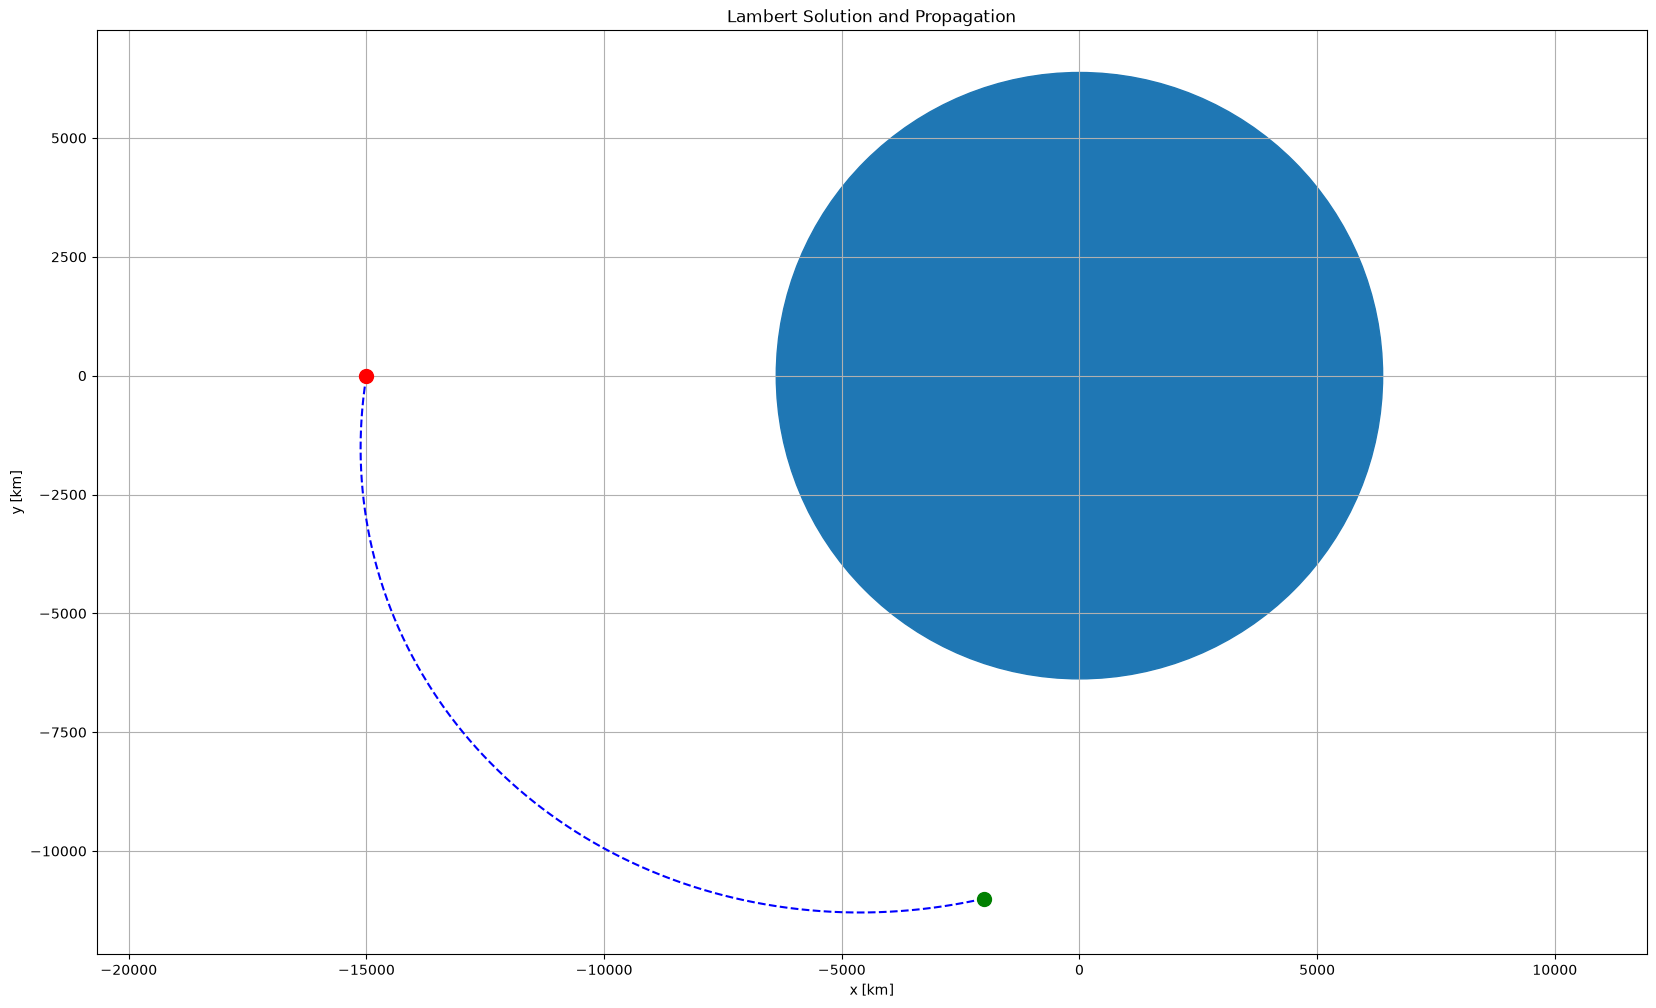

In [56]:
fig, ax = plt.subplots(figsize=(20, 12))
ax.set_title('Lambert Solution and Propagation')

# Trajectory
ax.plot(sol.y[0], sol.y[1], 'b--', label='Trajectory')

# Points
ax.plot(r1[0], r1[1], 'ro', markersize=10, label='r1')
ax.plot(r2[0], r2[1], 'go', markersize=10, label='r2')

# Body
ax.add_patch(plt.Circle((0,0), R_EARTH, color='tab:blue', fill=True))


ax.set_xlabel('x [km]')
ax.set_ylabel('y [km]')
ax.set_aspect('equal', adjustable='datalim')

ax.grid(True)
plt.show()

### Part c

In [57]:
from dynamics import two_body_with_J2
def ivp_two_body_with_J2(t,x):
    del t
    return two_body_with_J2(x)

sol_J2: np.ndarray = solve_ivp(ivp_two_body_with_J2, (0, tof), np.concatenate((r1, v1)), method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9)

In [58]:
print(f"Final r value [km]: \n\t{sol_J2.y[0:3, -1]}")
print(f"Goal r value [km]: \n\t{r2}")

err = r2-sol_J2.y[0:3,-1]
print(f"Err [km]:\n\t{err} ({norm(err):.4f} km)")
print("Not particularly well compared to Lambert")

Final r value [km]: 
	[ -1994.11083562 -10995.38903643      0.        ]
Goal r value [km]: 
	[ -2000 -11000      0]
Err [km]:
	[-5.88916438 -4.61096357  0.        ] (7.4795 km)
Not particularly well compared to Lambert


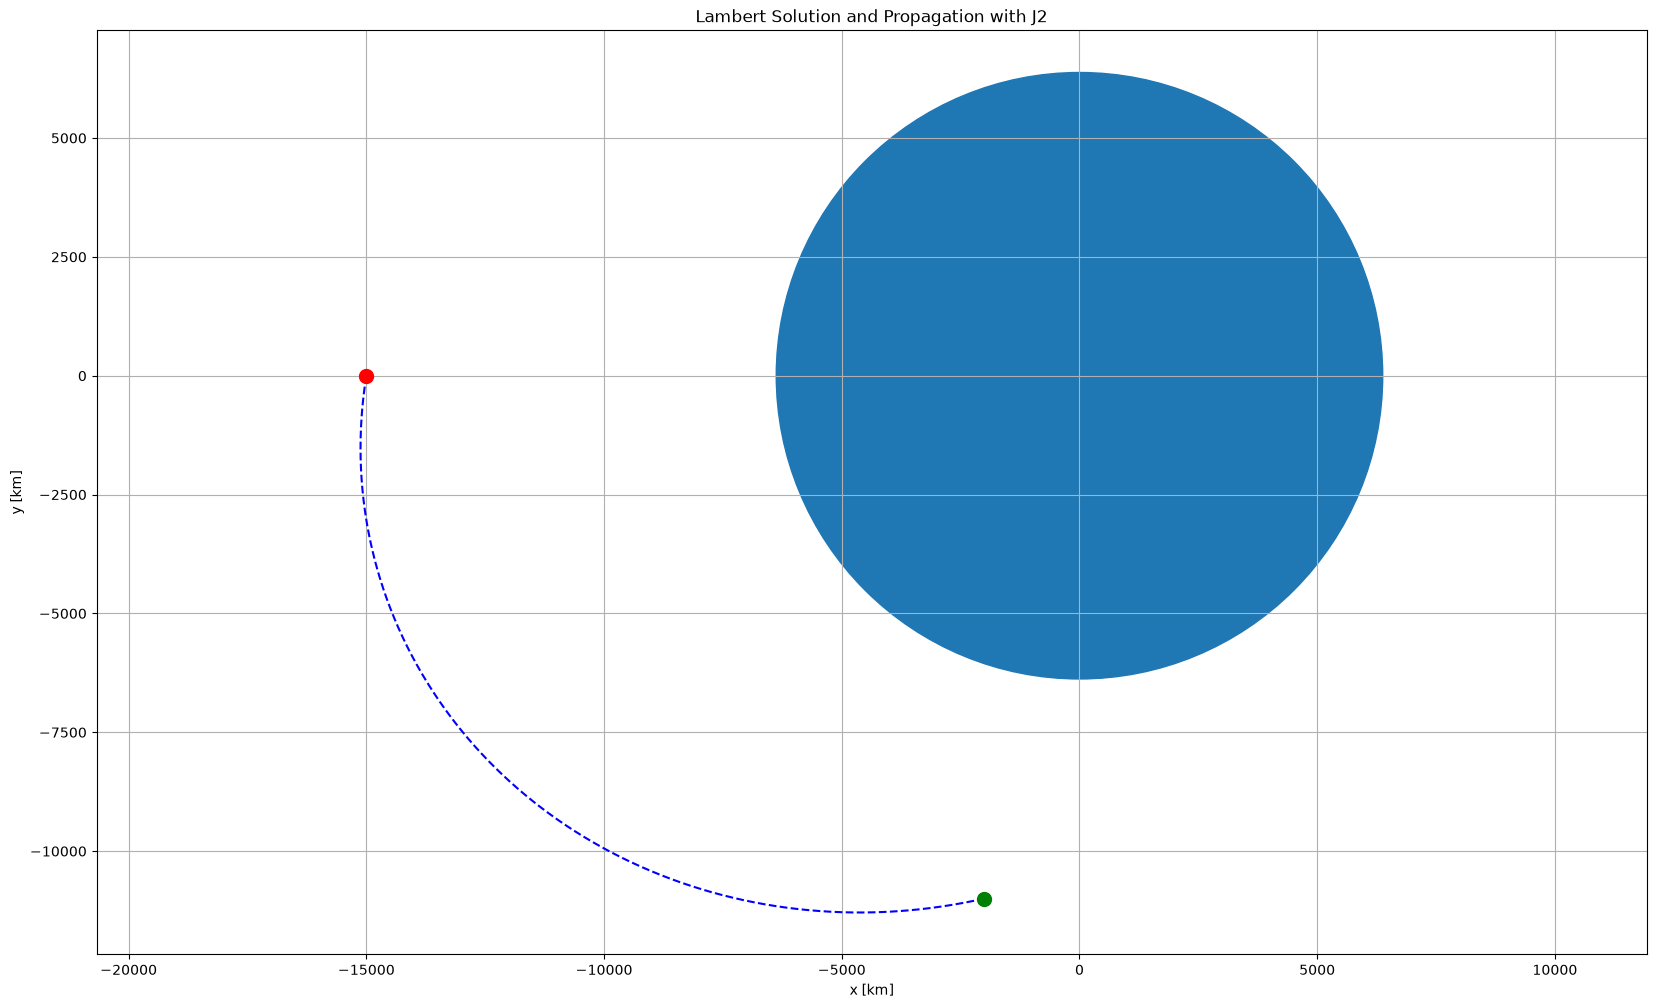

In [59]:
fig, ax = plt.subplots(figsize=(20, 12))
ax.set_title('Lambert Solution and Propagation with J2')

# Trajectory
ax.plot(sol_J2.y[0], sol_J2.y[1], 'b--', label='Trajectory')

# Points
ax.plot(r1[0], r1[1], 'ro', markersize=10, label='r1')
ax.plot(r2[0], r2[1], 'go', markersize=10, label='r2')

# Body
ax.add_patch(plt.Circle((0,0), R_EARTH, color='tab:blue', fill=True))


ax.set_xlabel('x [km]')
ax.set_ylabel('y [km]')
ax.set_aspect('equal', adjustable='datalim')

ax.grid(True)
plt.show()

### Part d

In [60]:
from guidance import AA279jacobianshoot
# def AA279jacobianshoot(odefun, tspan, y0in, dv, t_arr):
#     """
#     Returns 3x3 Jacobian for shooting method

#     AA279 Function Library
#     Last modified: 7 October 2026 by Andrew K. Barrows

#     Jacobian describes sensitivity of final position to initial velocity

#     State must be of the form [rx ry rz vx vy vz]'

#     sample function call:
#     J = jacobianshoot(@earthorbitbody, [0; 75*60], [r1; v1], 0.001)

#     odefun function handle for state derivative function
#     tspan trajectory start and end times [sec]
#     y0in state at which J should be evaluated
#     dv small velocity increment used for finite differences
#     t_arr array to be evaluated at
    
#     """

#     J = np.zeros((3,3))
#     y0in = np.asarray(y0in)

#     # vx
#     y0 = y0in + [0,0,0,dv,0,0]
#     sol = solve_ivp(odefun, (t_arr[0], t_arr[-1]), y0, method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9)
#     rhigh = sol.y[0:3, -1]
#     y0 = y0in + [0,0,0,-dv,0,0]
#     sol = solve_ivp(odefun, (t_arr[0], t_arr[-1]), y0, method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9)
#     rlow = sol.y[0:3, -1]
#     J[:, 0] = (rhigh-rlow)/(2*dv)

#     # vx
#     y0 = y0in + [0,0,0,0,dv,0]
#     sol = solve_ivp(odefun, (t_arr[0], t_arr[-1]), y0, method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9)
#     rhigh = sol.y[0:3, -1]
#     y0 = y0in + [0,0,0,0,-dv,0]
#     sol = solve_ivp(odefun, (t_arr[0], t_arr[-1]), y0, method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9)
#     rlow = sol.y[0:3, -1]
#     J[:, 1] = (rhigh-rlow)/(2*dv)

#     # vx
#     y0 = y0in + [0,0,0,0,0,dv]
#     sol = solve_ivp(odefun, (t_arr[0], t_arr[-1]), y0, method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9)
#     rhigh = sol.y[0:3, -1]
#     y0 = y0in + [0,0,0,0,0,-dv]
#     sol = solve_ivp(odefun, (t_arr[0], t_arr[-1]), y0, method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9)
#     rlow = sol.y[0:3, -1]
#     J[:, 2] = (rhigh-rlow)/(2*dv)

#     return J

In [61]:
def find_initial_conditions(t_arr, ode, state0, r_goal, iter = 10, convergence_bound = 10e-5, verbose = False):
    """10 cm bound"""

    
    tof = t_arr[-1]
    
    state = state0
    
    for i in range(iter):
        sim = solve_ivp(ode, (0, tof), state, method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9).y
        
        dr = sim[0:3,-1] - r_goal
        dr_norm = norm(dr)
        
        if verbose:
            print(f"dr: {dr_norm:.5f}km")
        
        if norm(dr) < convergence_bound:
            print(f"\nConverged in {i} iterations with:\n\tdr = {dr_norm:.5e} km")
            break
        
        J = AA279jacobianshoot(ode, (0, tof), state, dv=0.001, t_arr=t_arr)
        
        # Only adjusting velocity
        state[3:6] -= np.linalg.pinv(J) @ dr

    return state

state0_one_update = find_initial_conditions(t_arr, ivp_two_body_with_J2, np.concatenate((r1, v1)), r2, 1)
v1_one_update = state0_one_update[3:6]

In [62]:
print(f"Old v1 value [km/s]: \n\t{v1} ({norm(v1):.3f} km/s)")
print(f"Final v1 value [km/s]: \n\t{v1_one_update} ({norm(v1_one_update):.3f} km/s)")
# print(f"Difference [km/s]:\n\t{v1-v1_one_update}")
print()
diff_m = (v1-v1_one_update)*1000
print(f"Err [m/s]:\n\t{diff_m} ({norm(diff_m):.4f} m/s)")
print("Very small difference between original and 1 iteration")

Old v1 value [km/s]: 
	[-0.65513692 -4.06361027  0.        ] (4.116 km/s)
Final v1 value [km/s]: 
	[-6.55880947e-01 -4.06399723e+00 -6.45326496e-29] (4.117 km/s)

Err [m/s]:
	[7.44022005e-01 3.86958997e-01 6.45326496e-26] (0.8386 m/s)
Very small difference between original and 1 iteration


### Part e

In [63]:
sol_one_update: np.ndarray = solve_ivp(ivp_two_body_with_J2, (0, tof), state0_one_update, method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9).y

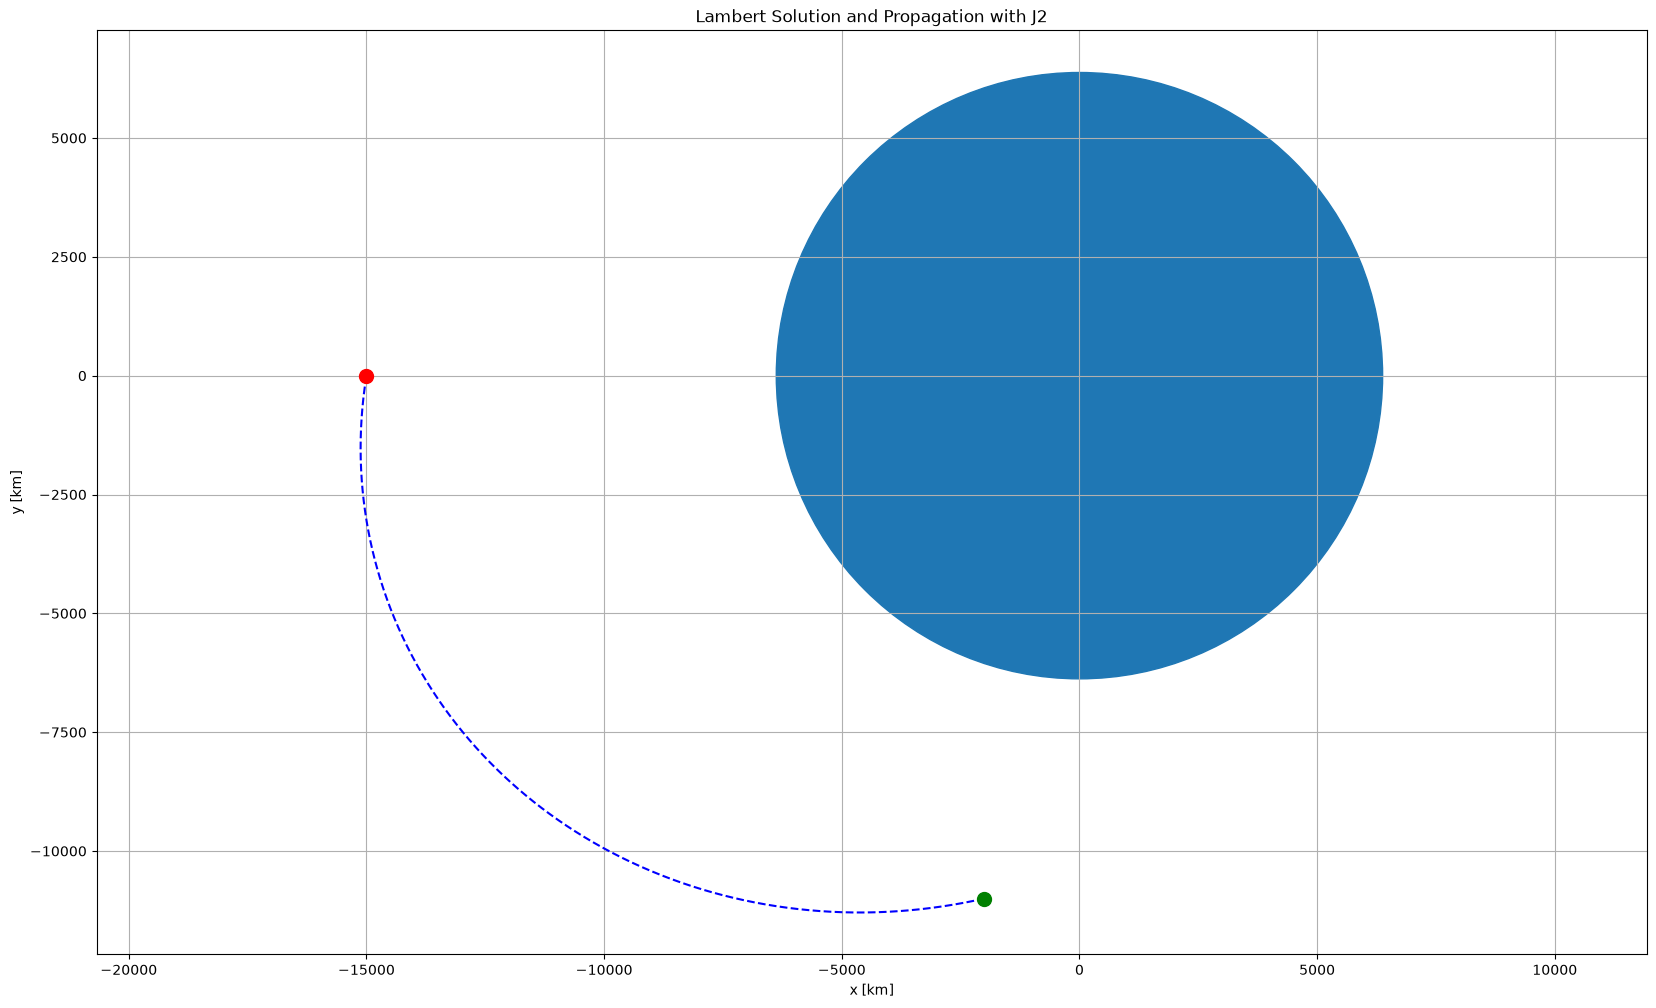

In [64]:
fig, ax = plt.subplots(figsize=(20, 12))
ax.set_title('Lambert Solution and Propagation with J2')

# Trajectory
ax.plot(sol_one_update[0], sol_one_update[1], 'b--', label='Trajectory')

# Points
ax.plot(r1[0], r1[1], 'ro', markersize=10, label='r1')
ax.plot(r2[0], r2[1], 'go', markersize=10, label='r2')

# Body
ax.add_patch(plt.Circle((0,0), R_EARTH, color='tab:blue', fill=True))


ax.set_xlabel('x [km]')
ax.set_ylabel('y [km]')
ax.set_aspect('equal', adjustable='datalim')

ax.grid(True)
plt.show()

### Part f

In [65]:
state0_full_updated = find_initial_conditions(t_arr, ivp_two_body_with_J2, np.concatenate((r1, v1)), r2)
v1_full_updated = state0_full_updated[3:6]


Converged in 2 iterations with:
	dr = 7.14902e-10 km


In [66]:
print(f"One-step v1 value [km/s]: \n\t{v1_one_update} ({norm(v1_one_update):.8f} km/s)")
print(f"Final Updated v1 value [km/s]: \n\t{v1_full_updated} ({norm(v1_full_updated):.8f} km/s)")
print()
print(f"Difference [km/s]:\n\t{v1_one_update-v1_full_updated}, ({norm(v1_one_update-v1_full_updated):.3e} km/s)")

One-step v1 value [km/s]: 
	[-6.55880947e-01 -4.06399723e+00 -6.45326496e-29] (4.11658272 km/s)
Final Updated v1 value [km/s]: 
	[-6.55880903e-01 -4.06399749e+00 -1.37271895e-32] (4.11658298 km/s)

Difference [km/s]:
	[-4.34135435e-08  2.62715839e-07 -6.45189224e-29], (2.663e-07 km/s)
